**Step 1 — Import Required Modules and Load the dataset**

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("phishing.csv")
print(df.head())
print(df.shape)
print(df.info())

   Index  UsingIP  LongURL  ShortURL  Symbol@  Redirecting//  PrefixSuffix-  \
0      0        1        1         1        1              1             -1   
1      1        1        0         1        1              1             -1   
2      2        1        0         1        1              1             -1   
3      3        1        0        -1        1              1             -1   
4      4       -1        0        -1        1             -1             -1   

   SubDomains  HTTPS  DomainRegLen  ...  UsingPopupWindow  IframeRedirection  \
0           0      1            -1  ...                 1                  1   
1          -1     -1            -1  ...                 1                  1   
2          -1     -1             1  ...                 1                  1   
3           1      1            -1  ...                -1                  1   
4           1      1            -1  ...                 1                  1   

   AgeofDomain  DNSRecording  WebsiteTraffic

**Step 2 — Understand the dataset**

In [3]:
df.describe()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
count,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,...,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000,11054.000000
mean,5526.500000,0.313914,-0.633345,0.738737,0.700561,0.741632,-0.734938,0.064049,0.251040,-0.336711,...,0.613353,0.816899,0.061335,0.377239,0.287407,-0.483626,0.721549,0.343948,0.719739,0.113986
std,3191.159272,0.949495,0.765973,0.674024,0.713625,0.670837,0.678165,0.817492,0.911856,0.941651,...,0.789845,0.576807,0.998162,0.926158,0.827680,0.875314,0.692395,0.569936,0.694276,0.993527
min,0.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,2763.250000,-1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,1.000000,1.000000,-1.000000,-1.000000,0.000000,-1.000000,1.000000,0.000000,1.000000,-1.000000
50%,5526.500000,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,1.000000,-1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,1.000000,1.000000
75%,8289.750000,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,11053.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Check missing values:

In [4]:
df.isnull().sum()

Index                  0
UsingIP                0
LongURL                0
ShortURL               0
Symbol@                0
Redirecting//          0
PrefixSuffix-          0
SubDomains             0
HTTPS                  0
DomainRegLen           0
Favicon                0
NonStdPort             0
HTTPSDomainURL         0
RequestURL             0
AnchorURL              0
LinksInScriptTags      0
ServerFormHandler      0
InfoEmail              0
AbnormalURL            0
WebsiteForwarding      0
StatusBarCust          0
DisableRightClick      0
UsingPopupWindow       0
IframeRedirection      0
AgeofDomain            0
DNSRecording           0
WebsiteTraffic         0
PageRank               0
GoogleIndex            0
LinksPointingToPage    0
StatsReport            0
class                  0
dtype: int64

Check duplicate records:

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
a=df.drop(columns=['class'])

In [7]:
a.head()

,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,DisableRightClick,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,1,-1,-1,0,-1,1,1,1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,1,-1,1,-1,1,0,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
3,3,1,0,-1,1,1,-1,1,1,-1,...,1,-1,1,-1,-1,0,-1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,1,-1,1,-1,-1


In [8]:
duplicate_indices = a.loc[
    a.duplicated(subset=a.columns.drop('Index')),
    'Index'
].to_numpy()

print(duplicate_indices)

[  179   202   235 ... 11050 11051 11052]


In [9]:
df=df.drop(duplicate_indices,axis=0)

In [10]:
df.shape

(5785, 32)

Check target distribution:

In [11]:
df['class'].value_counts()

class
-1    2984
 1    2801
Name: count, dtype: int64

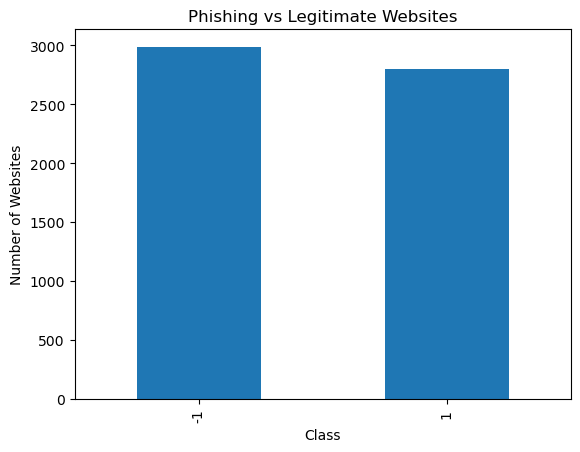

In [12]:
df['class'].value_counts().plot(kind='bar')
plt.xlabel("Class")
plt.ylabel("Number of Websites")
plt.title("Phishing vs Legitimate Websites")
plt.show()

**Step 3 — Data preprocessing**

First remove Index because it is only an identifier:

In [13]:
df = df.drop(columns=['Index'])

In [14]:
print(df.head())

   UsingIP  LongURL  ShortURL  Symbol@  Redirecting//  PrefixSuffix-  \
0        1        1         1        1              1             -1   
1        1        0         1        1              1             -1   
2        1        0         1        1              1             -1   
3        1        0        -1        1              1             -1   
4       -1        0        -1        1             -1             -1   

   SubDomains  HTTPS  DomainRegLen  Favicon  ...  UsingPopupWindow  \
0           0      1            -1        1  ...                 1   
1          -1     -1            -1        1  ...                 1   
2          -1     -1             1        1  ...                 1   
3           1      1            -1        1  ...                -1   
4           1      1            -1        1  ...                 1   

   IframeRedirection  AgeofDomain  DNSRecording  WebsiteTraffic  PageRank  \
0                  1           -1            -1               0      

Separate features and target:

In [15]:
X = df.drop(columns=['class'])
y = df['class']


Convert the target into a convenient binary representation:

In [16]:
y = y.map({-1: 1, 1: 0})

In [17]:
print(X.head())
print(y.head())

   UsingIP  LongURL  ShortURL  Symbol@  Redirecting//  PrefixSuffix-  \
0        1        1         1        1              1             -1   
1        1        0         1        1              1             -1   
2        1        0         1        1              1             -1   
3        1        0        -1        1              1             -1   
4       -1        0        -1        1             -1             -1   

   SubDomains  HTTPS  DomainRegLen  Favicon  ...  DisableRightClick  \
0           0      1            -1        1  ...                  1   
1          -1     -1            -1        1  ...                  1   
2          -1     -1             1        1  ...                  1   
3           1      1            -1        1  ...                  1   
4           1      1            -1        1  ...                  1   

   UsingPopupWindow  IframeRedirection  AgeofDomain  DNSRecording  \
0                 1                  1           -1            -1   
1 

**Step 4 — Exploratory Data Analysis**

In [18]:
df.columns

Index(['UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//',
       'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon',
       'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL',
       'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL',
       'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick',
       'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage',
       'StatsReport', 'class'],
      dtype='object')

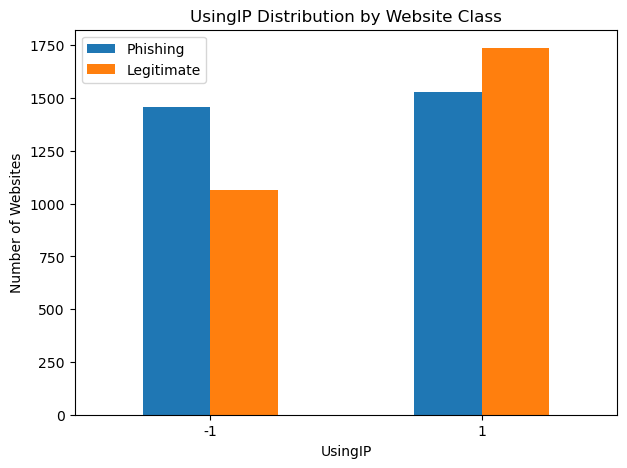

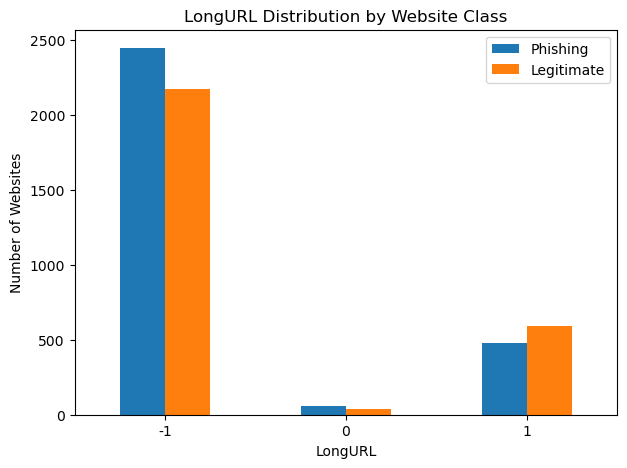

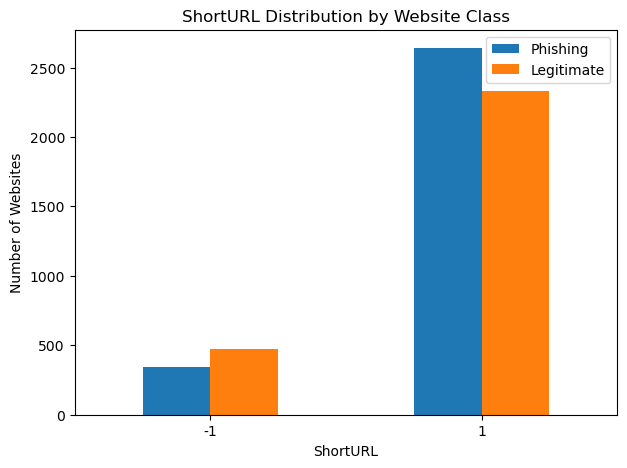

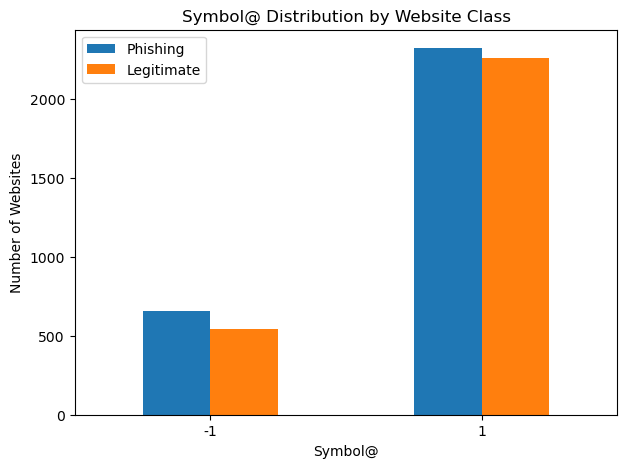

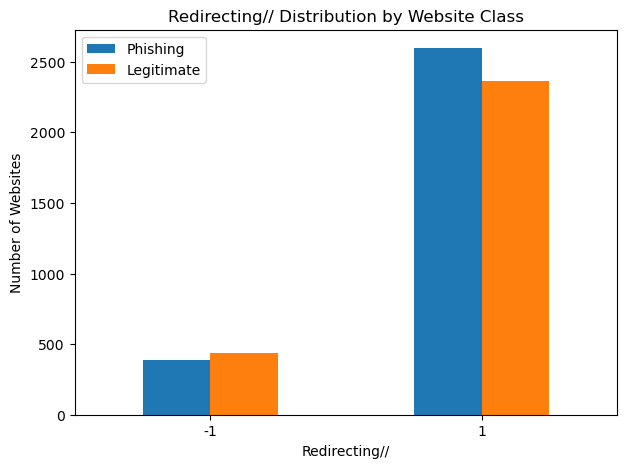

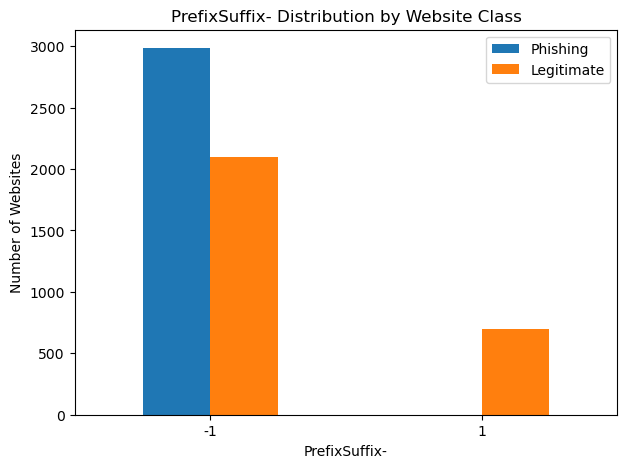

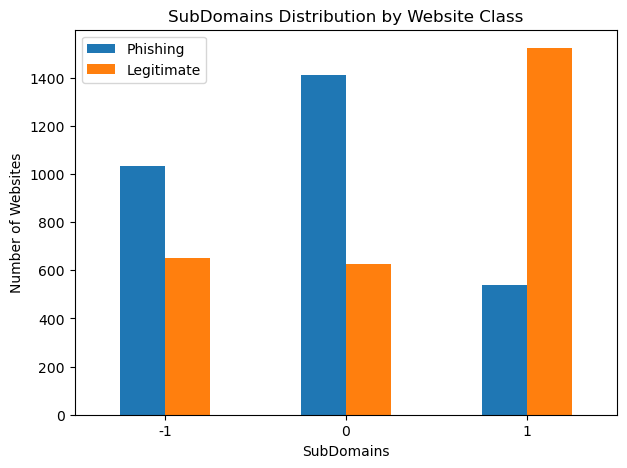

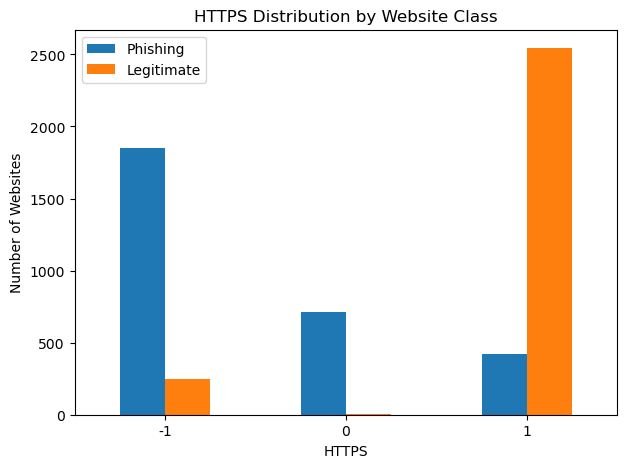

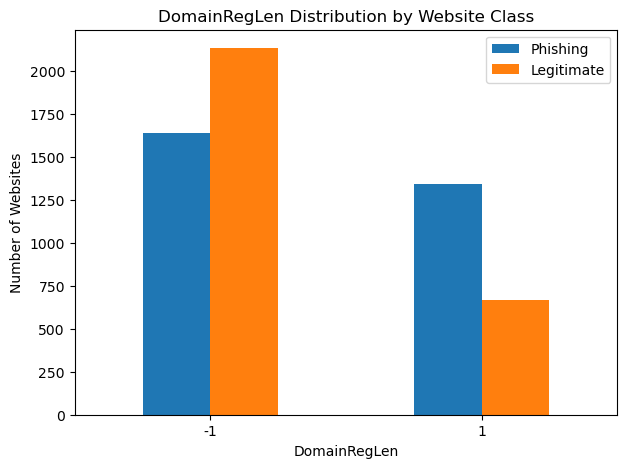

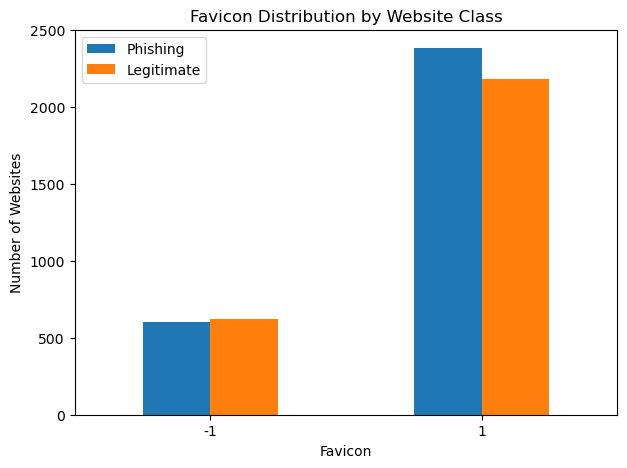

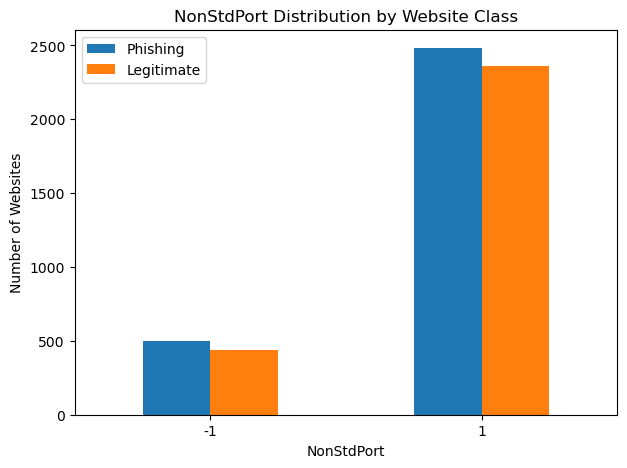

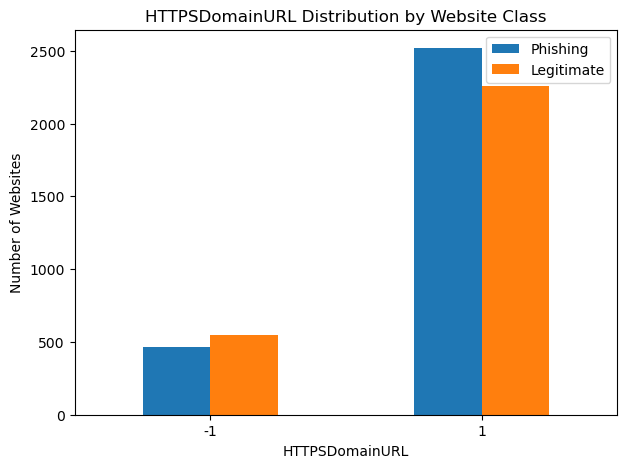

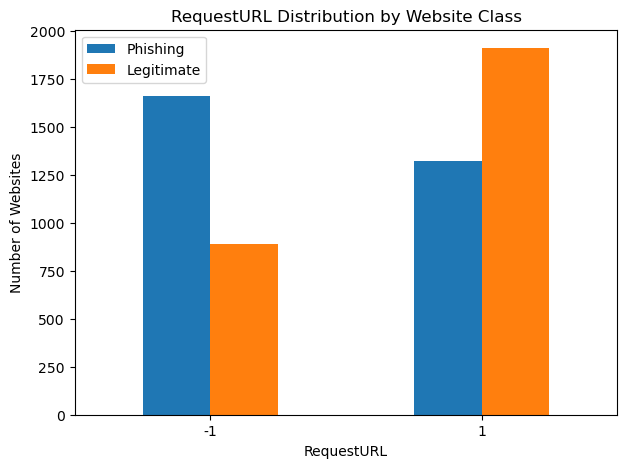

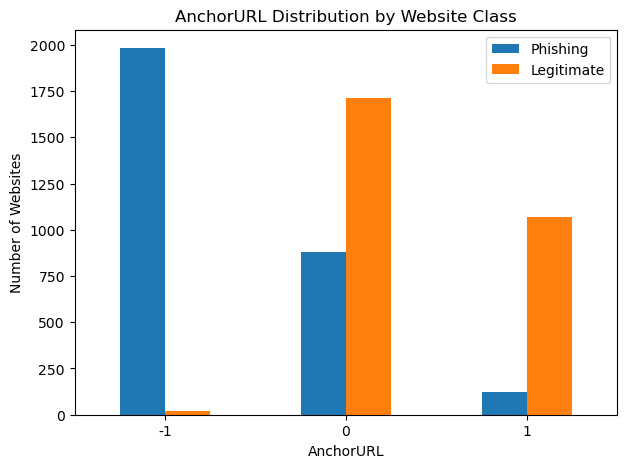

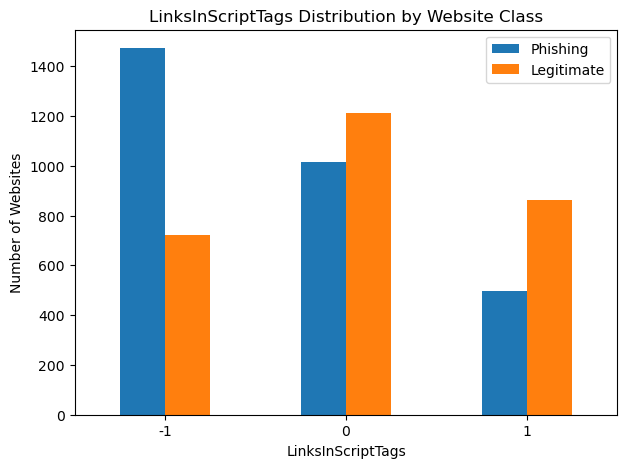

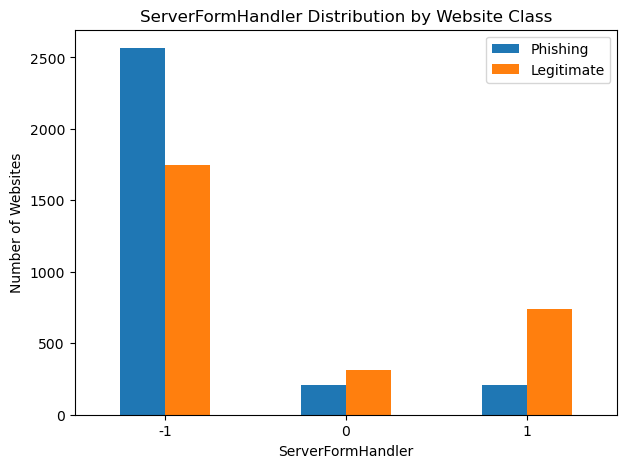

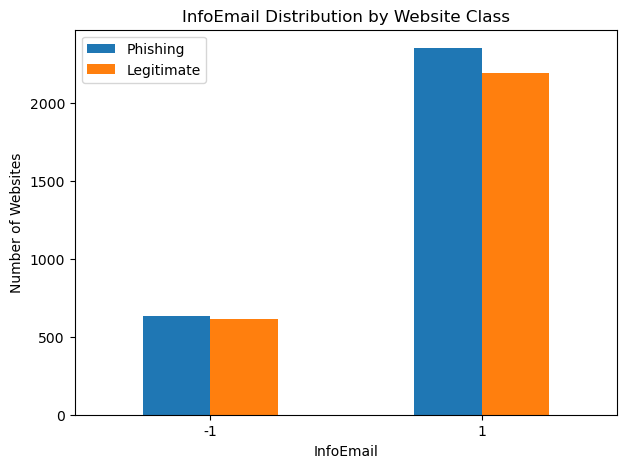

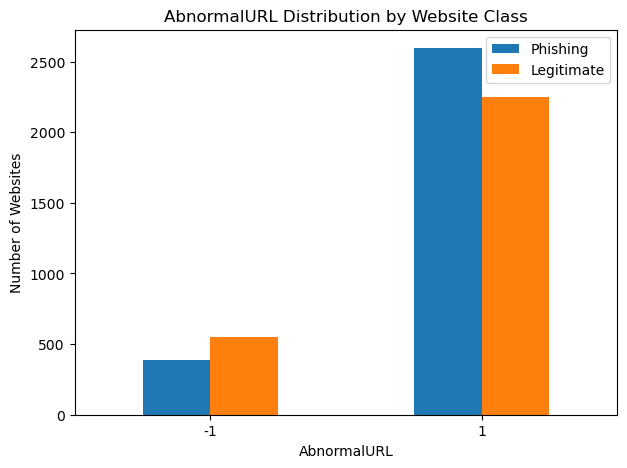

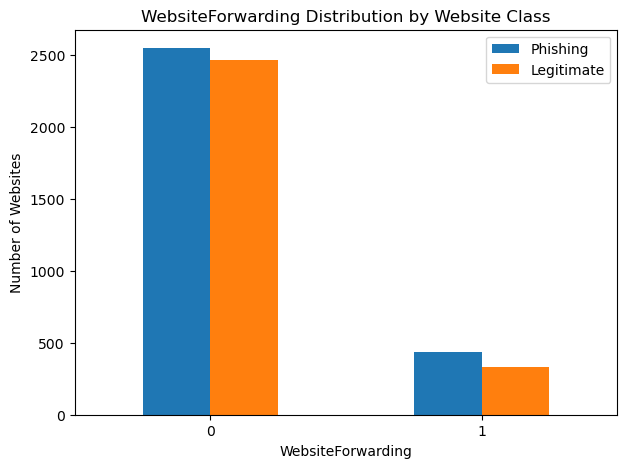

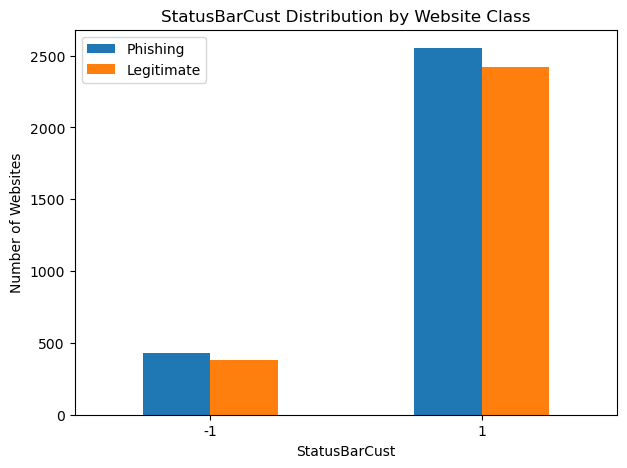

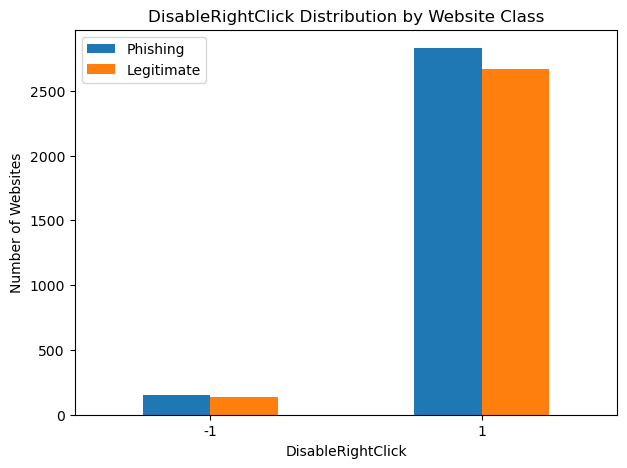

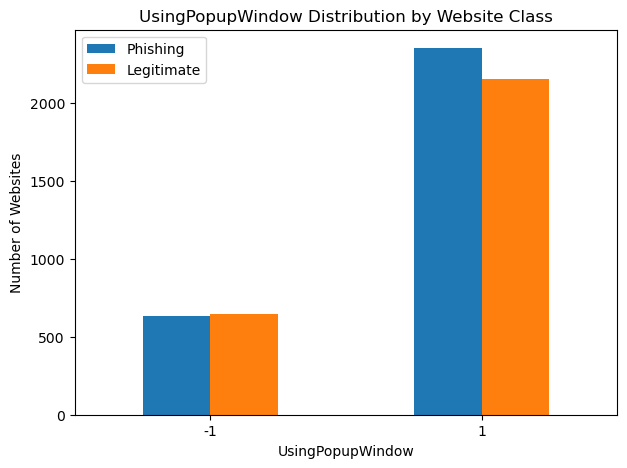

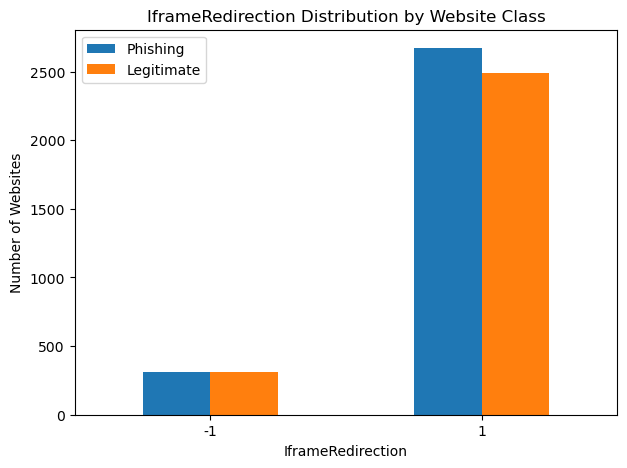

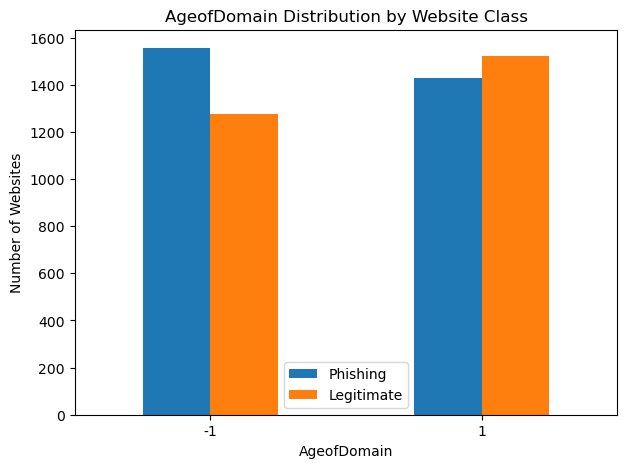

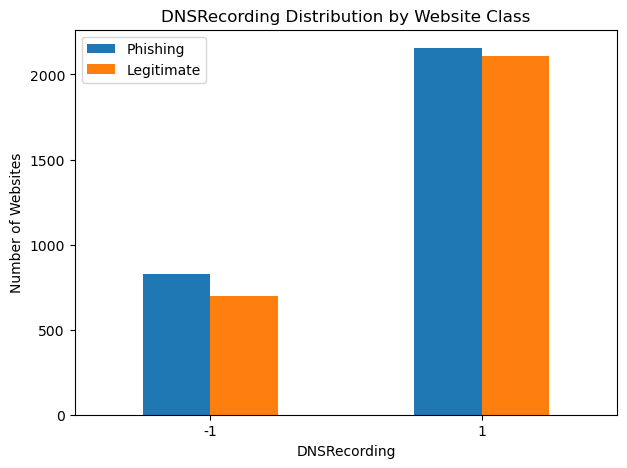

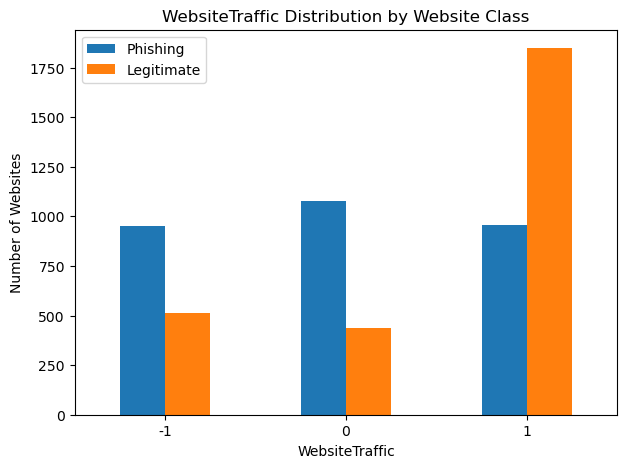

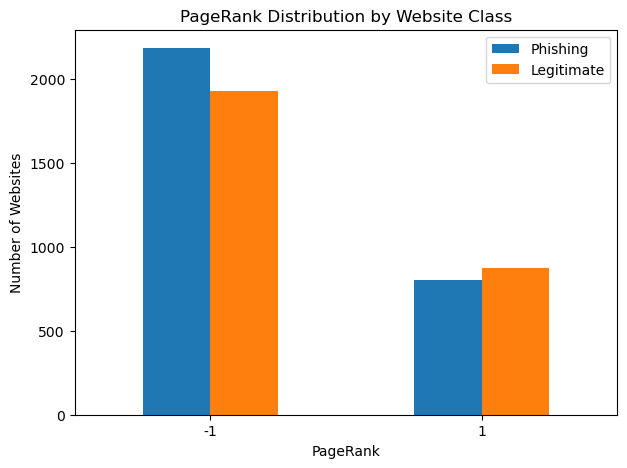

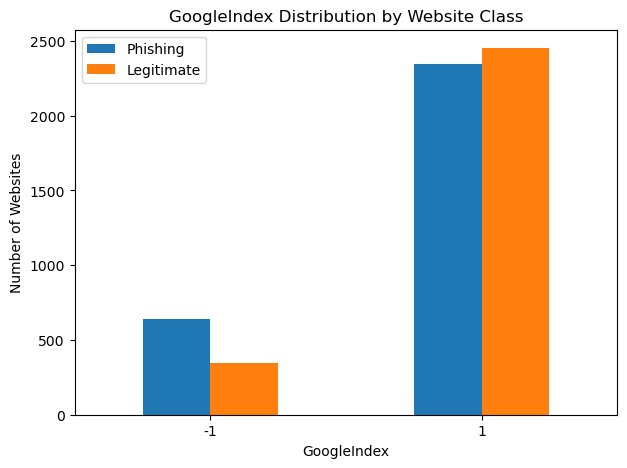

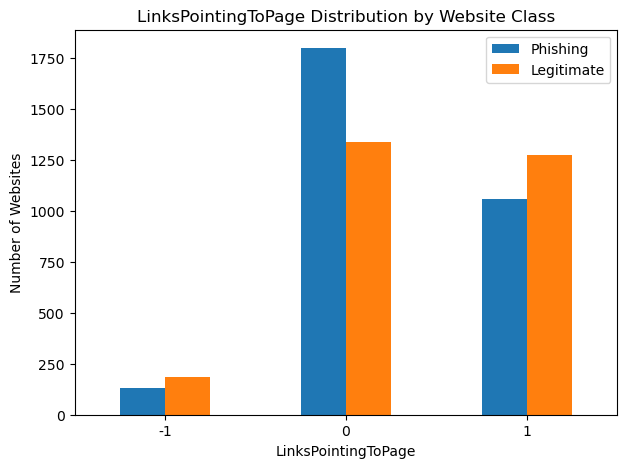

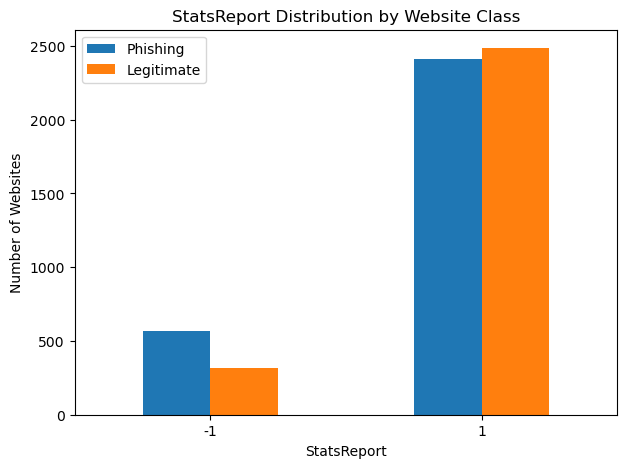

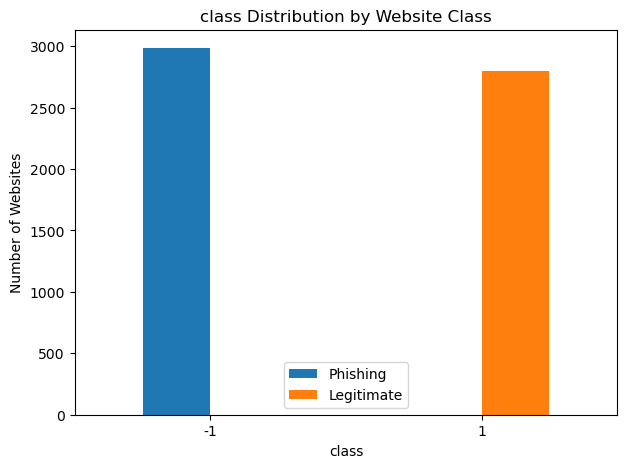

In [19]:

for feature in df.columns:

    distribution = pd.crosstab(
        df[feature],
        df['class']
    )

    distribution.plot(
        kind='bar',
        figsize=(7,5)
    )

    plt.title(f'{feature} Distribution by Website Class')
    plt.xlabel(feature)
    plt.ylabel('Number of Websites')
    plt.xticks(rotation=0)
    plt.legend(['Phishing', 'Legitimate'])

    plt.show()

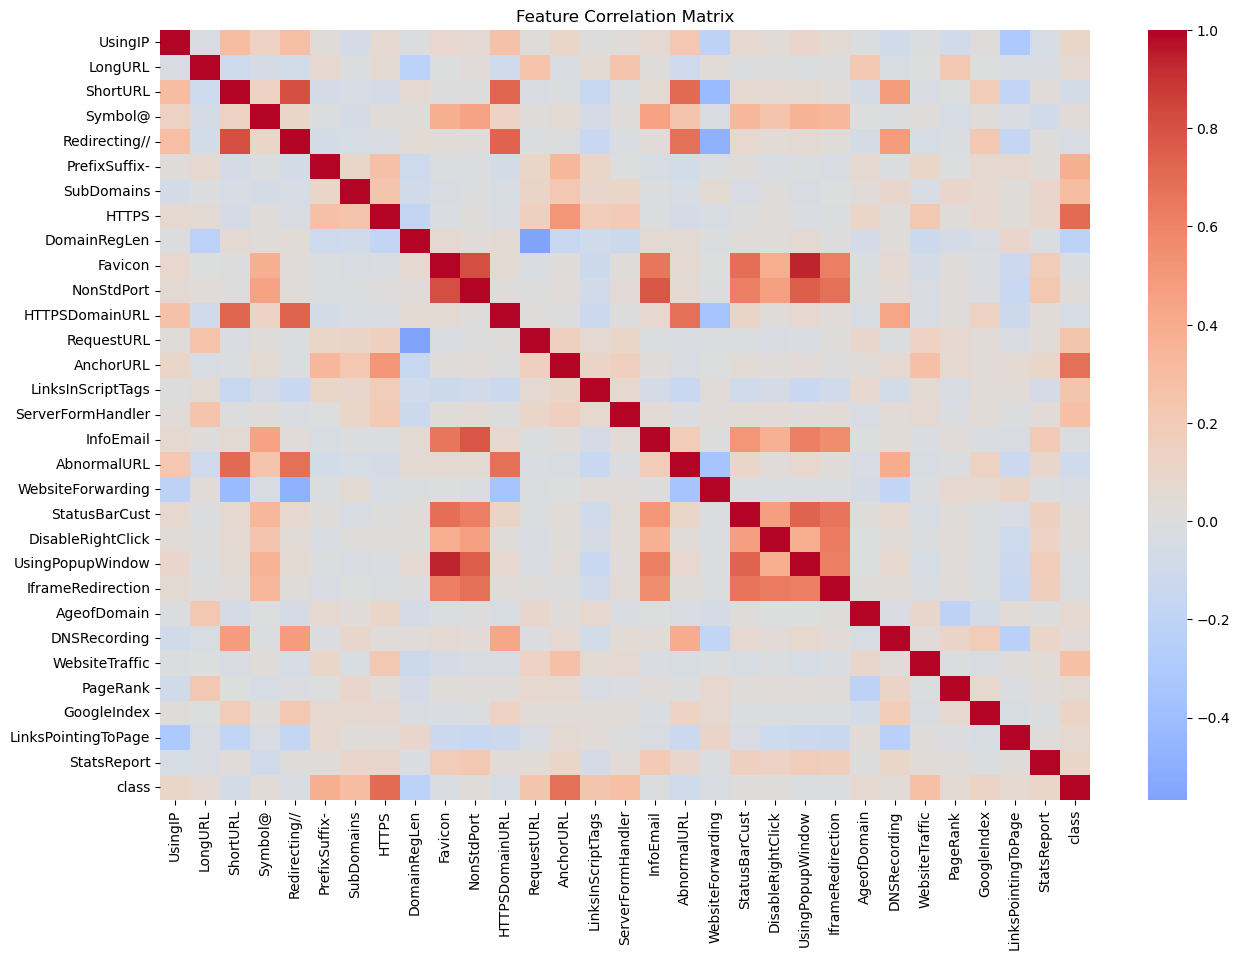

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15,10))
sns.heatmap(
    df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.show()

**Step 5 — Feature selection**

In [21]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X, y)

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

HTTPS                  0.319672
AnchorURL              0.236246
SubDomains             0.059402
WebsiteTraffic         0.054387
PrefixSuffix-          0.053881
LinksInScriptTags      0.042968
ServerFormHandler      0.032317
LinksPointingToPage    0.019738
RequestURL             0.018977
DomainRegLen           0.016188
UsingIP                0.015547
AgeofDomain            0.015070
PageRank               0.012428
GoogleIndex            0.012043
DNSRecording           0.010852
LongURL                0.010277
Symbol@                0.006998
WebsiteForwarding      0.006920
HTTPSDomainURL         0.006765
InfoEmail              0.005877
AbnormalURL            0.005769
UsingPopupWindow       0.005552
StatsReport            0.005491
ShortURL               0.005236
Favicon                0.005162
StatusBarCust          0.004383
Redirecting//          0.004337
IframeRedirection      0.002867
NonStdPort             0.002789
DisableRightClick      0.001861
dtype: float64


**Step 6 — Train-test split**

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

**Step 7 — Train multiple ML models**

In [23]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [24]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

In [25]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [26]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

In [27]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

**Step 8 — Compare the models**

Evaluate using:

Accuracy,
Precision,
Recall,
F1-score,
ROC-AUC,
Confusion Matrix.

In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(name, y_test, prediction):
    print(name)
    print("Accuracy :", accuracy_score(y_test, prediction))
    print("Precision:", precision_score(y_test, prediction))
    print("Recall   :", recall_score(y_test, prediction))
    print("F1 Score :", f1_score(y_test, prediction))
    print()

evaluate_model("Logistic Regression", y_test, lr_pred)
evaluate_model("Decision Tree", y_test, dt_pred)
evaluate_model("Random Forest", y_test, rf_pred)
evaluate_model("SVM", y_test, svm_pred)
evaluate_model("KNN", y_test, knn_pred)

Logistic Regression
Accuracy : 0.9325842696629213
Precision: 0.9466437177280551
Recall   : 0.9212730318257957
F1 Score : 0.933786078098472

Decision Tree
Accuracy : 0.9490060501296457
Precision: 0.9498327759197325
Recall   : 0.9514237855946399
F1 Score : 0.9506276150627615

Random Forest
Accuracy : 0.9628349178910977
Precision: 0.9726962457337884
Recall   : 0.9547738693467337
F1 Score : 0.9636517328825022

SVM
Accuracy : 0.9490060501296457
Precision: 0.9719298245614035
Recall   : 0.9279731993299832
F1 Score : 0.9494430162810625

KNN
Accuracy : 0.9351771823681936
Precision: 0.9364548494983278
Recall   : 0.9380234505862647
F1 Score : 0.9372384937238494



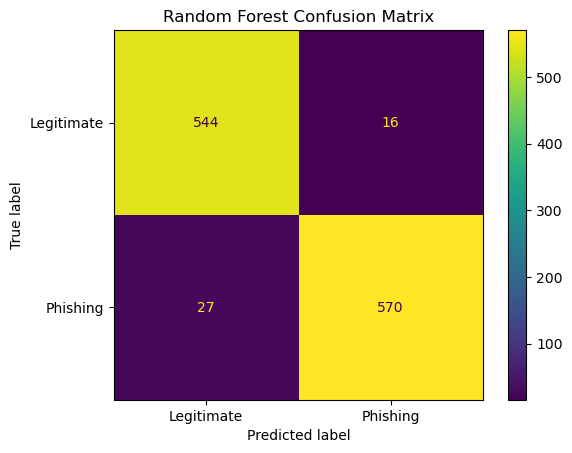

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, rf_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Phishing"]
).plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

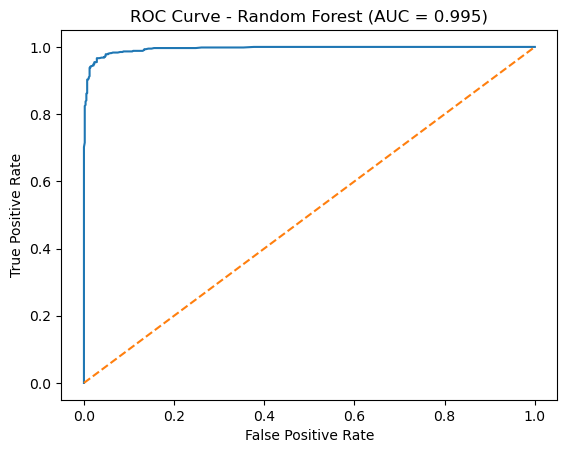

In [30]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

rf_prob = rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, rf_prob)

auc = roc_auc_score(y_test, rf_prob)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve - Random Forest (AUC = {auc:.3f})")

plt.show()

**Step 9 — Hyperparameter tuning**

In [31]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}
0.9603731178782855


In [32]:
best_model = grid.best_estimator_
print(best_model)

RandomForestClassifier(n_estimators=300, random_state=42)


In [33]:
import joblib

# Save trained model
joblib.dump(best_model, "model.pkl")

# Save EXACT feature names used during training
joblib.dump(X.columns.tolist(), "feature_names.pkl")

print("Model saved")
print("Features:", X.columns.tolist())

Model saved
Features: ['UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//', 'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon', 'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL', 'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL', 'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick', 'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording', 'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage', 'StatsReport']
